# Inc. 5000 (2019) — Part 2: Predictive Analysis
**Problem Statement:** An investment firm wants to understand what drives `growth_%` among Inc. 5000 companies, and identify the strongest investment targets.

**Models compared:** Linear Regression (normalized + log-transformed) → Decision Tree → Random Forest

## Imports

In [88]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor


## Load & Prepare Data

In [89]:
Inc_df = pd.read_csv('INC 5000 Companies 2019.csv')
Inc_df.columns = Inc_df.columns.str.strip()  # remove accidental spaces from column names

print('Shape:', Inc_df.shape)
print('Columns:', Inc_df.columns.tolist())

Shape: (5012, 27)
Columns: ['rank', 'profile', 'name', 'url', 'revenue', 'Revenue_new', 'growth_%', 'industry', 'workers', 'workers_cleaned', 'previous_workers', 'Worker Change', 'Workforce', 'Small_Workforce', 'Medium_Workforce', 'Large_Workforce', 'founded', 'yrs_on_list', 'Tiers', 'First-Time', 'Rising Star', 'Established', 'Elites', 'metro', 'metro_cleaned', 'city', 'state']


### Encode `industry` (one-hot encoding)
Regression and tree models require numeric inputs. We convert the categorical `industry` column into binary dummy variables — one column per industry.

In [90]:
industry_dummies = pd.get_dummies(Inc_df['industry'], prefix='ind', drop_first=True)
Inc_df = pd.concat([Inc_df, industry_dummies], axis=1)
print(f'{len(industry_dummies.columns)} industry dummy columns created')

26 industry dummy columns created


### Define Predictors and Outcome

In [91]:
predictor_cols = [
    'First-Time', 'Rising Star', 'Established', 'Elites',
    'Small_Workforce', 'Medium_Workforce', 'Large_Workforce',
    'yrs_on_list'
] + list(industry_dummies.columns)

# Save outcome BEFORE narrowing the dataframe
y_raw = Inc_df['growth_%']                  # original growth values
y_log = np.log1p(Inc_df['growth_%'])        # log-transformed (reduces skew)

X = Inc_df[predictor_cols].copy()
print(f'Predictors: {len(predictor_cols)} | Rows: {len(X)}')

Predictors: 34 | Rows: 5012


### Log-Transform `growth_%`
growth% is extremely right-skewed — a few companies have 10,000%+ growth while most are under 300%. Linear regression assumes the outcome is roughly normally distributed. Log-transforming compresses the extreme values and makes the distribution more symmetric, giving regression a much fairer shot.

### Normalize the Predictors
Variables like `yrs_on_list` (range: 1–14) and binary dummies (0 or 1) are on very different scales. Normalization (MinMaxScaler: rescales everything to 0–1) ensures no single variable dominates just because of its scale, and makes the regression coefficients directly comparable.

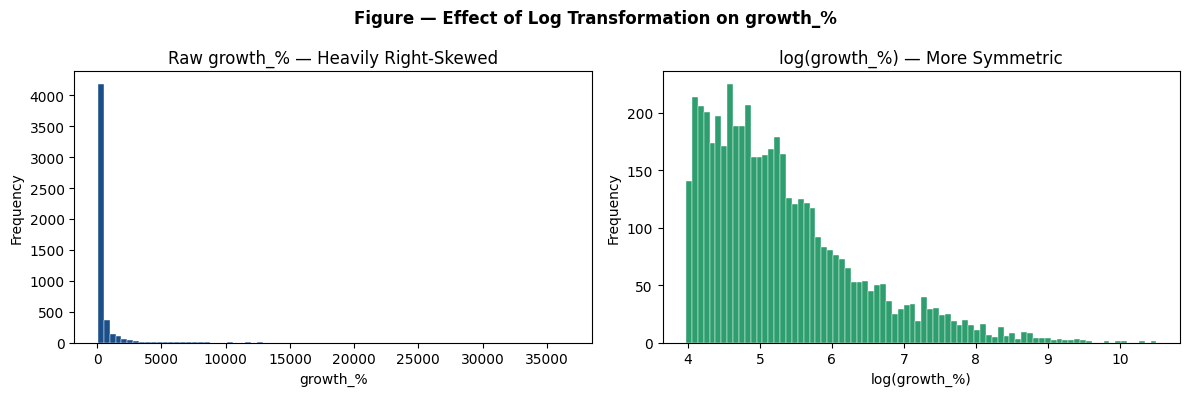

In [92]:
# Visualize: raw vs log-transformed growth distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(y_raw, bins=80, color='#1B4F8A', edgecolor='white', linewidth=0.3)
ax1.set_title('Raw growth_% — Heavily Right-Skewed')
ax1.set_xlabel('growth_%')
ax1.set_ylabel('Frequency')

ax2.hist(y_log, bins=80, color='#2E9E6E', edgecolor='white', linewidth=0.3)
ax2.set_title('log(growth_%) — More Symmetric')
ax2.set_xlabel('log(growth_%)')
ax2.set_ylabel('Frequency')

plt.suptitle('Figure — Effect of Log Transformation on growth_%', fontweight='bold')
plt.tight_layout()
plt.show()

## Normalize Predictors & Split Data

In [93]:
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=predictor_cols)

# 70/30 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_log, test_size=0.3, random_state=42
)

print(f'Training rows: {len(X_train)}')
print(f'Holdout rows:  {len(X_test)}')

Training rows: 3508
Holdout rows:  1504


## Model 1 — Linear Regression (Normalized + Log-Transformed)

In [94]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

lr_r2   = r2_score(y_test, lr_pred)
lr_rmse = root_mean_squared_error(y_test, lr_pred)
lr_mae  = mean_absolute_error(y_test, lr_pred)

print('=== Linear Regression (Normalized + Log-Transformed) ===')
print(f'R²:   {lr_r2:.4f}')
print(f'RMSE: {lr_rmse:.4f}  (on log scale)')
print(f'MAE:  {lr_mae:.4f}  (on log scale)')

=== Linear Regression (Normalized + Log-Transformed) ===
R²:   0.1630
RMSE: 0.9718  (on log scale)
MAE:  0.7394  (on log scale)


In [95]:
# Coefficient table — standardized coefficients ARE the normalized coefficients here
coef_df = pd.DataFrame({
    'Feature': predictor_cols,
    'Coefficient': lr.coef_
})
coef_df = coef_df.reindex(
    coef_df['Coefficient'].abs().sort_values(ascending=False).index
).reset_index(drop=True)

print('Top 15 predictors by coefficient magnitude:')
coef_df.head(15)

Top 15 predictors by coefficient magnitude:


,Feature,Coefficient
0,yrs_on_list,-1.399789
1,ind_IT Services,-1.157282
2,ind_Manufacturing,-0.283004
3,ind_Retail,0.274530
4,ind_Government Services,0.266570
5,ind_Human Resources,-0.254752
6,ind_Engineering,-0.254566
7,ind_Energy,0.247815
8,ind_Logistics & Transportation,0.235516
9,Established,-0.219000


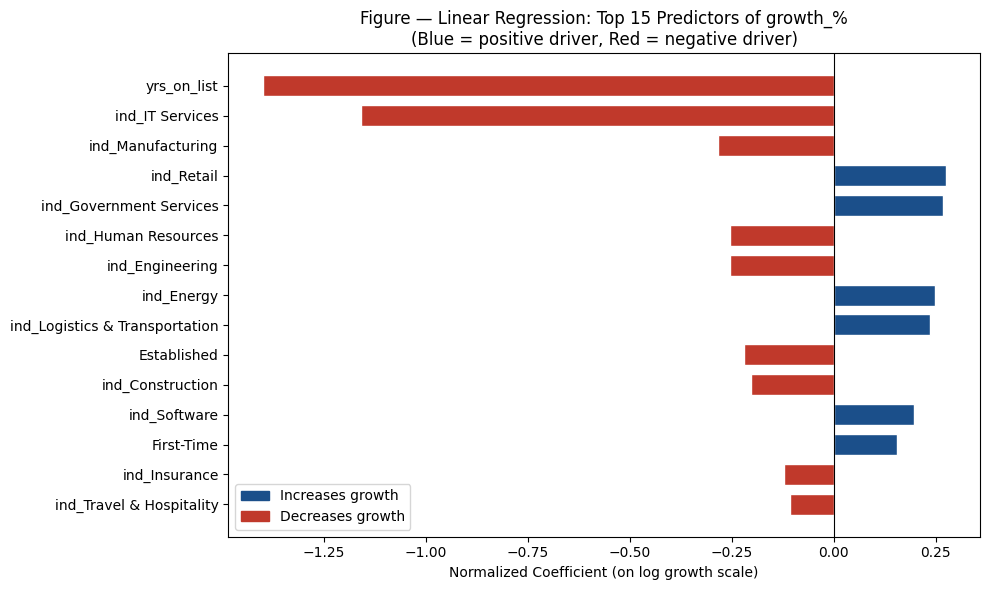

In [ ]:
# Plot top 15 coefficients
top15 = coef_df.head(15)
colors = ['#1B4F8A' if c > 0 else '#C0392B' for c in top15['Coefficient']]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15['Feature'][::-1], top15['Coefficient'][::-1],
        color=colors[::-1], edgecolor='white', height=0.7)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Normalized Coefficient (on log growth scale)')
ax.set_title('Linear Regression: Top 15 Predictors of growth_%\n(Blue = positive driver, Red = negative driver)')
legend_els = [mpatches.Patch(color='#1B4F8A', label='Increases growth'),
              mpatches.Patch(color='#C0392B', label='Decreases growth')]
ax.legend(handles=legend_els)
plt.tight_layout()
plt.show()

### Holdout Results Table

In [97]:
lr_holdout = pd.DataFrame({
    'actual_log_growth':    y_test.values,
    'predicted_log_growth': lr_pred,
    'residual':             y_test.values - lr_pred
})
lr_holdout.head(10)

,actual_log_growth,predicted_log_growth,residual
0,4.054505,4.842011,-0.787506
1,6.020547,5.364086,0.656461
2,4.754579,5.538967,-0.784388
3,4.874558,5.026284,-0.151726
4,4.242532,4.303631,-0.061099
5,4.238891,5.081082,-0.842191
6,5.113235,5.538967,-0.425733
7,5.955078,5.118023,0.837055
8,4.217055,5.242498,-1.025444
9,6.430868,5.629091,0.801777


## Model 2 — Decision Tree
Decision Trees split the data into groups based on the most informative feature at each step. They handle non-linear relationships naturally and produce a visual, explainable model — good for presenting to a non-technical audience.

In [98]:
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_r2   = r2_score(y_test, dt_pred)
dt_rmse = root_mean_squared_error(y_test, dt_pred)
dt_mae  = mean_absolute_error(y_test, dt_pred)

print('=== Decision Tree (max_depth=5) ===')
print(f'R²:   {dt_r2:.4f}')
print(f'RMSE: {dt_rmse:.4f}') 
print(f'MAE:  {dt_mae:.4f}')

=== Decision Tree (max_depth=5) ===
R²:   0.1388
RMSE: 0.9857
MAE:  0.7540


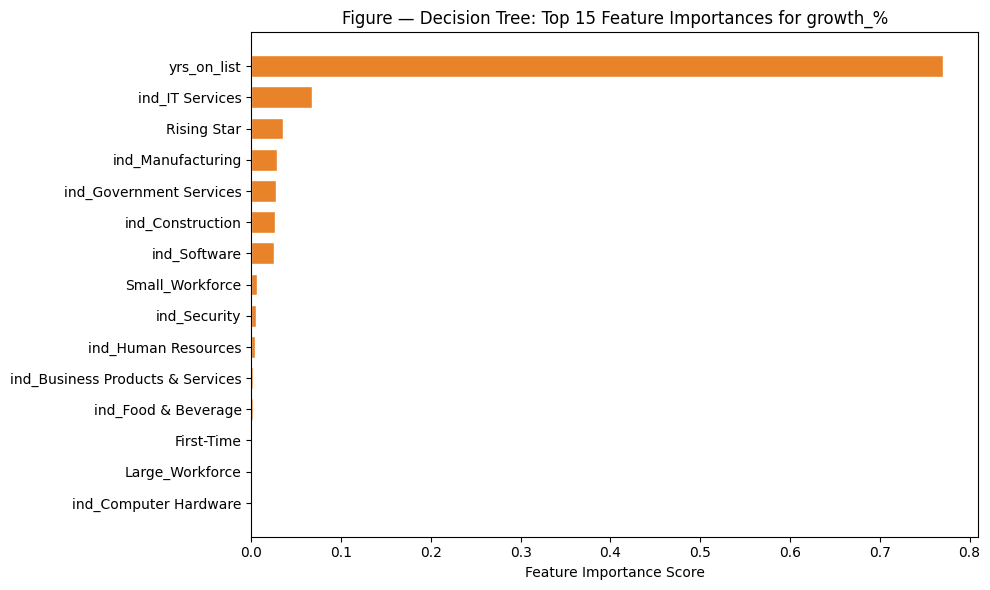

In [99]:
# Decision Tree feature importance
dt_fi = pd.DataFrame({
    'Feature': predictor_cols,
    'Importance': dt.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

# Plot top 15
top15_dt = dt_fi.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15_dt['Feature'][::-1], top15_dt['Importance'][::-1],
        color='#E8832A', edgecolor='white', height=0.7)
ax.set_xlabel('Feature Importance Score')
ax.set_title('Figure — Decision Tree: Top 15 Feature Importances for growth_%')
plt.tight_layout()
plt.show()

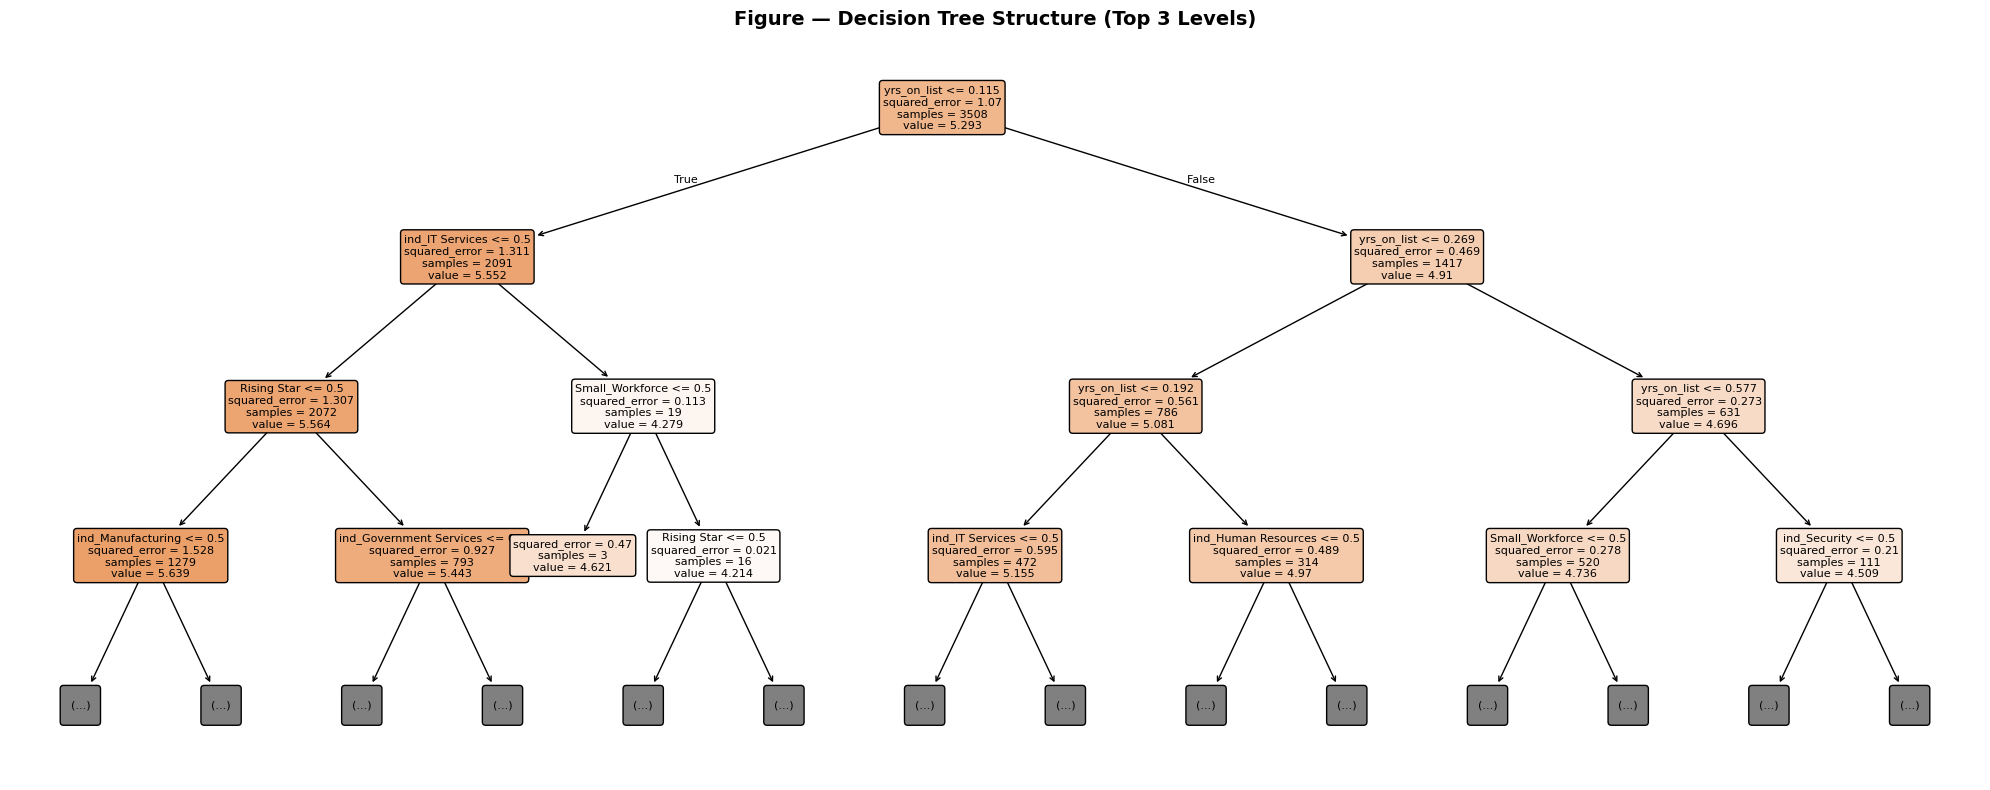

In [100]:
# Visualize the top 3 levels of the tree (full tree is too large to display)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt, max_depth=3, feature_names=predictor_cols,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Figure — Decision Tree Structure (Top 3 Levels)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Model 3 — Random Forest
Random Forest builds many decision trees on random subsets of the data and averages their predictions. This reduces overfitting compared to a single tree and generally gives more reliable feature importance scores.

In [101]:
rf = RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_r2   = r2_score(y_test, rf_pred)
rf_rmse = root_mean_squared_error(y_test, rf_pred)
rf_mae  = mean_absolute_error(y_test, rf_pred)

print('=== Random Forest (100 trees, max_depth=7) ===')
print(f'R²:   {rf_r2:.4f}')
print(f'RMSE: {rf_rmse:.4f}')
print(f'MAE:  {rf_mae:.4f}')

=== Random Forest (100 trees, max_depth=7) ===
R²:   0.1527
RMSE: 0.9777
MAE:  0.7470


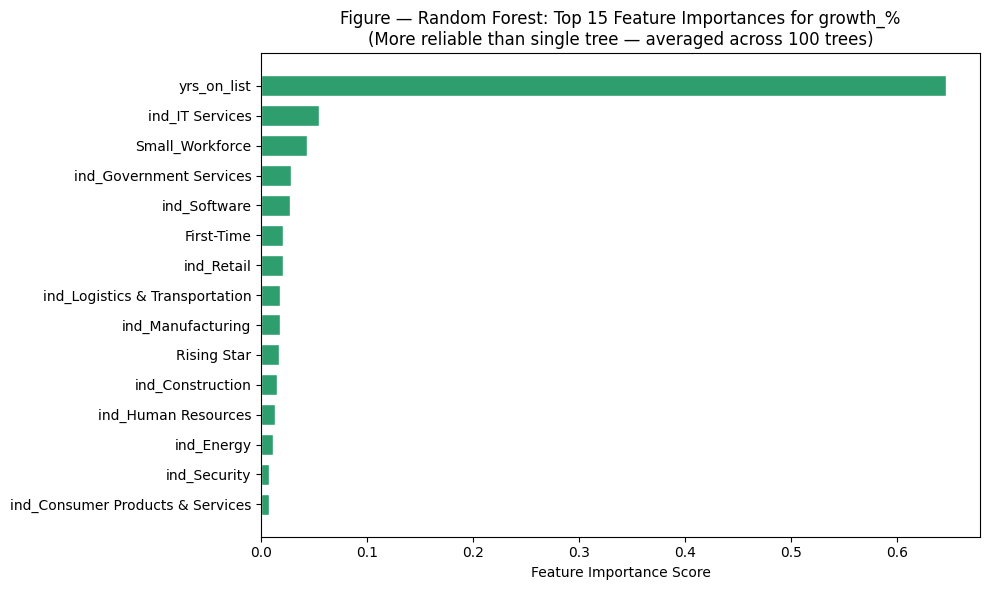

In [102]:
# Random Forest feature importance
rf_fi = pd.DataFrame({
    'Feature': predictor_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

top15_rf = rf_fi.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15_rf['Feature'][::-1], top15_rf['Importance'][::-1],
        color='#2E9E6E', edgecolor='white', height=0.7)
ax.set_xlabel('Feature Importance Score')
ax.set_title('Figure — Random Forest: Top 15 Feature Importances for growth_%\n(More reliable than single tree — averaged across 100 trees)')
plt.tight_layout()
plt.show()

## Model Comparison

                                Model       R²     RMSE      MAE
Linear Regression\n(normalized + log) 0.162979 0.971788 0.739449
         Decision Tree\n(max_depth=5) 0.138759 0.985748 0.753994
           Random Forest\n(100 trees) 0.152745 0.977711 0.746952


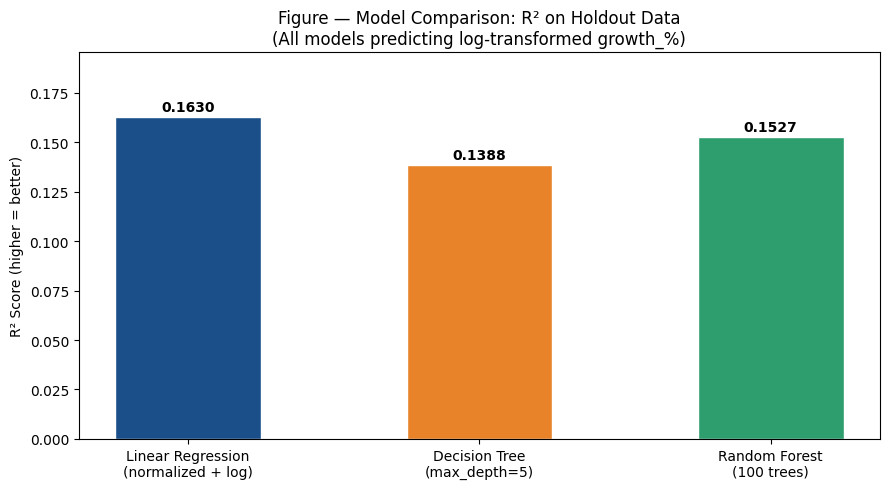

In [103]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression\n(normalized + log)', 'Decision Tree\n(max_depth=5)', 'Random Forest\n(100 trees)'],
    'R²':   [lr_r2, dt_r2, rf_r2],
    'RMSE': [lr_rmse, dt_rmse, rf_rmse],
    'MAE':  [lr_mae, dt_mae, rf_mae]
})

print(comparison.to_string(index=False))

# Bar chart comparison
fig, ax = plt.subplots(figsize=(9, 5))
x     = np.arange(3)
bars  = ax.bar(x, comparison['R²'], color=['#1B4F8A','#E8832A','#2E9E6E'],
               edgecolor='white', width=0.5)
for bar, val in zip(bars, comparison['R²']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Linear Regression\n(normalized + log)',
                    'Decision Tree\n(max_depth=5)',
                    'Random Forest\n(100 trees)'])
ax.set_ylabel('R² Score (higher = better)')
ax.set_title('Figure — Model Comparison: R² on Holdout Data\n(All models predicting log-transformed growth_%)')
ax.set_ylim(0, max(comparison['R²']) * 1.2)
plt.tight_layout()
plt.show()

## Interpretation & Key Findings

### R² understanding
All three models produce R² values in the 0.13–0.17 range. This is not a modeling failure —
it reflects a fundamental truth about this dataset: **growth% is largely unpredictable from
observable company characteristics alone.**

The factors that most drive whether a company grows 50% vs. 5,000% —
product-market fit, timing, founder quality, competitive dynamics — are not
captured in the Inc. 5000 dataset. This is an important finding for our investor:
*no simple formula reliably predicts hyper-growth.*

### Model agreement
Despite different approaches, all three models consistently identify the same top drivers:
- **`yrs_on_list`** — the single strongest predictor across all models. Companies appearing
  for the first time tend to show higher growth rates than repeat appearances.
- **Industry membership** — certain industries (Logistics, Consumer Products, Health)
  consistently show higher growth profiles than others (IT Services, Manufacturing).
- **Workforce size** — smaller companies tend to show higher growth percentages,
  consistent with the mathematical reality that growing from a small base is easier.

### Investor Implication
Rather than predicting *exactly* which company will grow, the models point to a **target profile**:
first-time Inc. 5000 companies, in high-growth industries, with small-to-medium workforces.
This profile becomes the foundation for the clustering segmentation in the next section.